In [3]:
!pip install pandas
!pip install mongo
!pip install matplotlib
!pip install seaborn

In [4]:
#importo le libreirie necessarie per analizzare i dati
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import re

In [5]:
#importo i dati dal database di MongoDB e creo il mio data_set locale
from pymongo import MongoClient

client=MongoClient('mongodb://localhost:27017')
db=client['Football_Data']
collection_games=db['Games']
documents=collection_games.find()
games_df=pd.DataFrame(list(documents)).drop('_id', axis=1)

games_df

,game_id,competition_id,season,round,date,home_club_id,away_club_id,home_club_goals,away_club_goals,home_club_position,...,stadium,attendance,referee,url,home_club_name,away_club_name,aggregate,competition_type,home_club_formation,away_club_formation
0,2222597,RU1,2012,6. Matchday,2012-08-25,3725,232,2,1,2.0,...,Akhmat-Arena,21700.0,Vladislav Bezborodov,https://www.transfermarkt.co.uk/terek-grozny_s...,RFK Akhmat Grozny,FK Spartak Moskva,2:1,domestic_league,NaN,NaN
1,2222627,RU1,2012,5. Matchday,2012-08-20,2696,4128,0,2,11.0,...,Metallurg,11400.0,Sergey Ivanov,https://www.transfermarkt.co.uk/krylya-sovetov...,PFK Krylya Sovetov Samara,Amkar Perm,0:2,domestic_league,NaN,NaN
2,2222658,RU1,2012,10. Matchday,2012-09-30,2410,121,0,2,2.0,...,Arena Khimki,12000.0,Sergey Karasev,https://www.transfermarkt.co.uk/cska-moscow_di...,PFK CSKA Moskva,FK Dinamo Moskva,0:2,domestic_league,NaN,NaN
3,2222664,RU1,2012,8. Matchday,2012-09-15,932,2698,1,0,5.0,...,RZD Arena,11408.0,Sergey Karasev,https://www.transfermarkt.co.uk/lokomotiv-mosc...,"Футбольный клуб ""Локомотив"" Москва",FC Rubin Kazan,1:0,domestic_league,NaN,NaN
4,2222683,RU1,2012,12. Matchday,2012-10-22,2696,12438,0,1,11.0,...,Metallurg,7534.0,Timur Arslanbekov,https://www.transfermarkt.co.uk/krylya-sovetov...,PFK Krylya Sovetov Samara,Volga Nizhniy Novgorod (- 2016),0:1,domestic_league,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
65211,2367292,EL,2013,Group B,2013-11-07,383,419,2,0,NaN,...,Philips Stadion,10000.0,Cristian Balaj,https://www.transfermarkt.co.uk/spielbericht/i...,Eindhovense Voetbalvereniging Philips Sport Ve...,NaN,2:0,international_cup,NaN,NaN
65212,2629035,NLP,2015,Third Round,2015-10-27,383,16866,6,0,NaN,...,Philips Stadion,31000.0,Allard Lindhout,https://www.transfermarkt.co.uk/spielbericht/i...,Eindhovense Voetbalvereniging Philips Sport Ve...,NaN,6:0,domestic_cup,NaN,NaN
65213,3092951,CLQ,2018,Qualifying Round 2nd leg,2018-08-29,383,713,3,0,NaN,...,Philips Stadion,34200.0,Anthony Taylor,https://www.transfermarkt.co.uk/spielbericht/i...,Eindhovense Voetbalvereniging Philips Sport Ve...,NaN,3:0,international_cup,NaN,NaN
65214,4164101,CGB,2023,Second Round,2023-08-29,512,1194,6,1,NaN,...,bet365 Stadium,9410.0,Michael Salisbury,https://www.transfermarkt.co.uk/spielbericht/i...,Stoke City,NaN,6:1,other,4-2-3-1,4-2-3-1


In [6]:
#Possiamo osservare che alcuni dati sono difficilmente leggibili, quelli il cui nome della squadra è in cirillico. Provo ad analizzare i dati
#per trovare le squadre e provare a toglierli (es tabelle sopra Футбольный клуб "Локомотив" Москва)

#importo i dati necessari per trovare la nazionalità dei club, partendo dal csv dei club
club_df= pd.read_csv('clubs.csv')
club_df.columns

Index(['club_id', 'club_code', 'name', 'domestic_competition_id',
       'total_market_value', 'squad_size', 'average_age', 'foreigners_number',
       'foreigners_percentage', 'national_team_players', 'stadium_name',
       'stadium_seats', 'net_transfer_record', 'coach_name', 'last_season',
       'url'],
      dtype='object')

In [7]:
#Mantengo solo le colonne interessanti, ovvero il club_id (che mi servirà per collegarlo al home_club_id/away_club_id) e
#la domestic_competition_id tramite la quale troverò la nazionalità
club_domestic_df=club_df[['club_id','domestic_competition_id']]

In [8]:
#importo i dati dal csv delle competizioni
competitions_df= pd.read_csv('competitions.csv')
competitions_df.columns

Index(['competition_id', 'competition_code', 'name', 'sub_type', 'type',
       'country_id', 'country_name', 'domestic_league_code', 'confederation',
       'url'],
      dtype='object')

In [9]:
#Mantengo solo le colonne interessanti, ovvero il domestic_league_code (con cui mi collego ai club) e il nome della nazione
competitions_domestic_df=competitions_df[['domestic_league_code', 'country_name']]

In [10]:
# Metto in join i dati delle partite con i dati dei club e delle competizioni. Qui considero solamente 'home_club'
merged_df = pd.merge(games_df, club_domestic_df, left_on='home_club_id', right_on='club_id')
merged_df = pd.merge(merged_df, competitions_domestic_df, left_on='domestic_competition_id', right_on='domestic_league_code')

#analizzo solamente i dati necessari per analizzare le squadre: Nazione (mi interessa sapere se tutte le squadre di una data nazione hanno il nome
#in cirillico), nome del club (per trovare quelli in cirillico) e id per poterlo in caso eliminare
merged_df=merged_df[['country_name', 'home_club_name', 'home_club_id']]
merged_df=merged_df[~merged_df['home_club_name'].duplicated()]

#funzione usata per trovare i testi in cirillico
def contains_cyricclic(text):
    return bool(re.search(('[\u0400-\u04ff]'), text))
    
#Squadre di calcio con il nome in cirillico
df_filtered=merged_df[merged_df['home_club_name'].apply(contains_cyricclic)]
df_filtered

,country_name,home_club_name,home_club_id
9,Russia,"Футбольный клуб ""Локомотив"" Москва",932


In [11]:
# Metto in join i dati delle partite con i dati dei club e delle competizioni. Qui considero solamente 'away_club'
merged_df = pd.merge(games_df, club_domestic_df, left_on='away_club_id', right_on='club_id')
merged_df = pd.merge(merged_df, competitions_domestic_df, left_on='domestic_competition_id', right_on='domestic_league_code')

#analizzo solamente i dati necessari per analizzare le squadre: Nazione (mi interessa sapere se tutte le squadre di una data nazione hanno il nome
#in cirillico), nome del club (per trovare quelli in cirillico) e id per poterlo in caso eliminare
merged_df=merged_df[['country_name', 'away_club_name', 'away_club_id']]
merged_df=merged_df[~merged_df['away_club_name'].duplicated()]

#funzione usata per trovare i testi in cirillico
def contains_cyricclic(text):
    return bool(re.search(('[\u0400-\u04ff]'), text))
    
#Squadre di calcio con il nome in cirillico
df_filtered=merged_df[merged_df['away_club_name'].apply(contains_cyricclic)]
df_filtered

,country_name,away_club_name,away_club_id
710,Russia,"Футбольный клуб ""Локомотив"" Москва",932


In [12]:
#E' presente solamente una squadra con il nome in cirillico, la elimino dal dataset

games_df = games_df[~(games_df['away_club_id'].isin(df_filtered['away_club_id'])|games_df['home_club_id'].isin(df_filtered['away_club_id']))]
games_df

,game_id,competition_id,season,round,date,home_club_id,away_club_id,home_club_goals,away_club_goals,home_club_position,...,stadium,attendance,referee,url,home_club_name,away_club_name,aggregate,competition_type,home_club_formation,away_club_formation
0,2222597,RU1,2012,6. Matchday,2012-08-25,3725,232,2,1,2.0,...,Akhmat-Arena,21700.0,Vladislav Bezborodov,https://www.transfermarkt.co.uk/terek-grozny_s...,RFK Akhmat Grozny,FK Spartak Moskva,2:1,domestic_league,NaN,NaN
1,2222627,RU1,2012,5. Matchday,2012-08-20,2696,4128,0,2,11.0,...,Metallurg,11400.0,Sergey Ivanov,https://www.transfermarkt.co.uk/krylya-sovetov...,PFK Krylya Sovetov Samara,Amkar Perm,0:2,domestic_league,NaN,NaN
2,2222658,RU1,2012,10. Matchday,2012-09-30,2410,121,0,2,2.0,...,Arena Khimki,12000.0,Sergey Karasev,https://www.transfermarkt.co.uk/cska-moscow_di...,PFK CSKA Moskva,FK Dinamo Moskva,0:2,domestic_league,NaN,NaN
4,2222683,RU1,2012,12. Matchday,2012-10-22,2696,12438,0,1,11.0,...,Metallurg,7534.0,Timur Arslanbekov,https://www.transfermarkt.co.uk/krylya-sovetov...,PFK Krylya Sovetov Samara,Volga Nizhniy Novgorod (- 2016),0:1,domestic_league,NaN,NaN
5,2222685,RU1,2012,19. Matchday,2012-12-10,2698,232,0,1,7.0,...,Central Stadium Kazan,8384.0,Vladislav Bezborodov,https://www.transfermarkt.co.uk/rubin-kazan_sp...,FC Rubin Kazan,FK Spartak Moskva,0:1,domestic_league,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
65211,2367292,EL,2013,Group B,2013-11-07,383,419,2,0,NaN,...,Philips Stadion,10000.0,Cristian Balaj,https://www.transfermarkt.co.uk/spielbericht/i...,Eindhovense Voetbalvereniging Philips Sport Ve...,NaN,2:0,international_cup,NaN,NaN
65212,2629035,NLP,2015,Third Round,2015-10-27,383,16866,6,0,NaN,...,Philips Stadion,31000.0,Allard Lindhout,https://www.transfermarkt.co.uk/spielbericht/i...,Eindhovense Voetbalvereniging Philips Sport Ve...,NaN,6:0,domestic_cup,NaN,NaN
65213,3092951,CLQ,2018,Qualifying Round 2nd leg,2018-08-29,383,713,3,0,NaN,...,Philips Stadion,34200.0,Anthony Taylor,https://www.transfermarkt.co.uk/spielbericht/i...,Eindhovense Voetbalvereniging Philips Sport Ve...,NaN,3:0,international_cup,NaN,NaN
65214,4164101,CGB,2023,Second Round,2023-08-29,512,1194,6,1,NaN,...,bet365 Stadium,9410.0,Michael Salisbury,https://www.transfermarkt.co.uk/spielbericht/i...,Stoke City,NaN,6:1,other,4-2-3-1,4-2-3-1


In [13]:
#tramite la descrizione riesco ad osservare il data_set totale. Da qui posso già notare che il numero di goal massimi è elevato
#provo a pulire i dati prima di considerarlo un errore 
games_df.describe()

,game_id,season,date,home_club_id,away_club_id,home_club_goals,away_club_goals,home_club_position,away_club_position,attendance
count,6.477500e+04,64775.000000,64775,64775.000000,64775.000000,64775.000000,64775.000000,45416.000000,45416.000000,55268.000000
mean,3.017716e+06,2017.251378,2018-03-07 04:33:22.328058368,4925.401636,4444.039290,1.594519,1.322069,9.289832,9.472477,18102.623001
min,2.211607e+06,2012.000000,2012-07-03 00:00:00,1.000000,2.000000,0.000000,0.000000,1.000000,1.000000,1.000000
25%,2.518106e+06,2014.000000,2015-04-04 00:00:00,354.000000,347.000000,1.000000,0.000000,5.000000,5.000000,4270.000000
50%,2.919811e+06,2017.000000,2018-01-29 00:00:00,1003.000000,989.000000,1.000000,1.000000,9.000000,9.000000,12179.000000
75%,3.450780e+06,2020.000000,2021-02-08 00:00:00,3205.000000,3030.000000,2.000000,2.000000,14.000000,14.000000,26307.250000
max,4.228114e+06,2023.000000,2023-11-30 00:00:00,112753.000000,112755.000000,15.000000,19.000000,21.000000,21.000000,99354.000000
std,5.604905e+05,3.349040,NaN,11455.437124,10273.099127,1.428038,1.364267,5.303623,5.325440,17808.114723


In [14]:
#tramite la shape osservo il numero di righe e colonne
games_df.shape

(64775, 23)

In [15]:
games_df.dtypes

game_id                            int64
competition_id                    object
season                             int64
round                             object
date                      datetime64[ns]
home_club_id                       int64
away_club_id                       int64
home_club_goals                    int64
away_club_goals                    int64
home_club_position               float64
away_club_position               float64
home_club_manager_name            object
away_club_manager_name            object
stadium                           object
attendance                       float64
referee                           object
url                               object
home_club_name                    object
away_club_name                    object
aggregate                         object
competition_type                  object
home_club_formation               object
away_club_formation               object
dtype: object

In [16]:
games_df.columns

Index(['game_id', 'competition_id', 'season', 'round', 'date', 'home_club_id',
       'away_club_id', 'home_club_goals', 'away_club_goals',
       'home_club_position', 'away_club_position', 'home_club_manager_name',
       'away_club_manager_name', 'stadium', 'attendance', 'referee', 'url',
       'home_club_name', 'away_club_name', 'aggregate', 'competition_type',
       'home_club_formation', 'away_club_formation'],
      dtype='object')

In [17]:
#le colonne che seleziono sono quelle che posso considerare più utili nell'analisi di una partita. E' molto imporatnte analizzare le stagioni,
#le varie date, tener conto del nome della squadra e del goal fatto. Può essere anche interessante analizzare se in percentuale si fanno più goal
#se la squadra è a casa rispetto che in uscita o se il numero di goal è direttamente proporzionale alla posizione in classifica (più la squadra è forte
#più fa goal) o se è in relazione alla posizione dell'altra squadra (più la squadra avversaria è debole più faccio goal)
df=games_df[['game_id','season', 'competition_type','round','date','home_club_name',
       'away_club_name', 'home_club_goals', 'away_club_goals', 'home_club_position', 'away_club_position',
       'home_club_formation', 'away_club_formation']]
df=df[~df.duplicated()]
df

,game_id,season,competition_type,round,date,home_club_name,away_club_name,home_club_goals,away_club_goals,home_club_position,away_club_position,home_club_formation,away_club_formation
0,2222597,2012,domestic_league,6. Matchday,2012-08-25,RFK Akhmat Grozny,FK Spartak Moskva,2,1,2.0,5.0,NaN,NaN
1,2222627,2012,domestic_league,5. Matchday,2012-08-20,PFK Krylya Sovetov Samara,Amkar Perm,0,2,11.0,10.0,NaN,NaN
2,2222658,2012,domestic_league,10. Matchday,2012-09-30,PFK CSKA Moskva,FK Dinamo Moskva,0,2,2.0,13.0,NaN,NaN
4,2222683,2012,domestic_league,12. Matchday,2012-10-22,PFK Krylya Sovetov Samara,Volga Nizhniy Novgorod (- 2016),0,1,11.0,16.0,NaN,NaN
5,2222685,2012,domestic_league,19. Matchday,2012-12-10,FC Rubin Kazan,FK Spartak Moskva,0,1,7.0,5.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
65211,2367292,2013,international_cup,Group B,2013-11-07,Eindhovense Voetbalvereniging Philips Sport Ve...,NaN,2,0,NaN,NaN,NaN,NaN
65212,2629035,2015,domestic_cup,Third Round,2015-10-27,Eindhovense Voetbalvereniging Philips Sport Ve...,NaN,6,0,NaN,NaN,NaN,NaN
65213,3092951,2018,international_cup,Qualifying Round 2nd leg,2018-08-29,Eindhovense Voetbalvereniging Philips Sport Ve...,NaN,3,0,NaN,NaN,NaN,NaN
65214,4164101,2023,other,Second Round,2023-08-29,Stoke City,NaN,6,1,NaN,NaN,4-2-3-1,4-2-3-1


In [18]:
#controllo di aver eliminato i duplicati, per fare questo prima controllo che l'id sia unico e dopo lo setterò a indice
duplicati = df[df.duplicated('game_id', keep=False)]
duplicati

,game_id,season,competition_type,round,date,home_club_name,away_club_name,home_club_goals,away_club_goals,home_club_position,away_club_position,home_club_formation,away_club_formation


In [19]:
df=df.set_index('game_id')

In [20]:
# Controllo che non ci siano duplicati controllando che non ci siano partite nello stesso giorno giocate dalle stesse due squadre.

#Prima creo una colonna temporanea con i valori da analizzare
df['combined'] = df['date'].astype(str) + '_' + df['home_club_name'].astype(str) + '_' + df['away_club_name'].astype(str)

# Trovo i duplicati basandomi sulla colonna combinata
duplicati = df[df.duplicated('combined', keep=False)]

duplicati

,season,competition_type,round,date,home_club_name,away_club_name,home_club_goals,away_club_goals,home_club_position,away_club_position,home_club_formation,away_club_formation,combined
game_id,,,,,,,,,,,,,
2231981,2012,international_cup,First Round 2nd leg,2012-07-10,NaN,NaN,3,4,NaN,NaN,NaN,NaN,2012-07-10_nan_nan
2231994,2012,international_cup,Second Round 1st leg,2012-07-18,NaN,NaN,1,1,NaN,NaN,NaN,NaN,2012-07-18_nan_nan
2231996,2012,international_cup,Second Round 1st leg,2012-07-17,NaN,NaN,0,1,NaN,NaN,NaN,NaN,2012-07-17_nan_nan
2232001,2012,international_cup,Second Round 2nd leg,2012-07-24,NaN,NaN,2,0,NaN,NaN,NaN,NaN,2012-07-24_nan_nan
2232097,2012,international_cup,First Round 1st leg,2012-07-05,NaN,NaN,0,1,NaN,NaN,NaN,NaN,2012-07-05_nan_nan
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4093501,2023,international_cup,Second Round 1st leg,2023-07-27,NaN,NaN,3,0,NaN,NaN,4-3-3 Attacking,3-5-2 flat,2023-07-27_nan_nan
4156993,2023,domestic_cup,First Round,2023-08-27,NaN,NaN,1,4,NaN,NaN,4-2-3-1,4-2-3-1,2023-08-27_nan_nan
4126931,2023,domestic_cup,Second Round,2023-08-23,NaN,NaN,1,2,NaN,NaN,4-4-2 double 6,4-4-2 double 6,2023-08-23_nan_nan


In [21]:
#Per l'analisi delle partite non mi interessano dati in cui non conoscono i due partecipanti e il risultato, quindi elimino
#tutte le informazioni in cui questi sono nulli
df=df[~df['home_club_name'].isna()]
df=df[~df['away_club_name'].isna()]
df=df[~df['home_club_goals'].isna()]
df=df[~df['away_club_goals'].isna()]
Na=df[(df['home_club_name'].isna())|(df['away_club_name'].isna())|(df['home_club_goals'].isna())|(df['away_club_goals'].isna())]
Na

,season,competition_type,round,date,home_club_name,away_club_name,home_club_goals,away_club_goals,home_club_position,away_club_position,home_club_formation,away_club_formation,combined
game_id,,,,,,,,,,,,,


In [22]:
# Provo a rivisualizzare i possibili duplicati. Non sono presenti
df['combined'] = df['date'].astype(str) + '_' + df['home_club_name'].astype(str) + '_' + df['away_club_name'].astype(str)
duplicati = df[df.duplicated('combined', keep=False)]
duplicati

,season,competition_type,round,date,home_club_name,away_club_name,home_club_goals,away_club_goals,home_club_position,away_club_position,home_club_formation,away_club_formation,combined
game_id,,,,,,,,,,,,,


In [23]:
#analizzo più in dettaglio i dati. Stagioni ha un minimo e un massimo accettabili, come anche le posizioni dei club di calcio.
#il numero di goal invece sembra corretto fino al 75%, ma poi c'è un numero massimo di goal molto elevato che potrebbe essere
#un errore di battitura
df.describe()

,season,date,home_club_goals,away_club_goals,home_club_position,away_club_position
count,51215.000000,51215,51215.000000,51215.000000,45416.000000,45416.000000
mean,2017.170185,2018-02-24 19:40:33.997852160,1.554271,1.222103,9.289832,9.472477
min,2012.000000,2012-07-09 00:00:00,0.000000,0.000000,1.000000,1.000000
25%,2014.000000,2015-03-22 00:00:00,1.000000,0.000000,5.000000,5.000000
50%,2017.000000,2018-01-19 00:00:00,1.000000,1.000000,9.000000,9.000000
75%,2020.000000,2021-01-29 00:00:00,2.000000,2.000000,14.000000,14.000000
max,2023.000000,2023-11-30 00:00:00,14.000000,15.000000,21.000000,21.000000
std,3.317009,NaN,1.337951,1.206252,5.303623,5.325440


In [24]:
df.shape

(51215, 13)

In [25]:
#outlier dei goal delle squadre che giocano in casa, oltre al 75% (il numero di goal è di 2) per vedere la frequenza di goal. Fino al 75%
#dei dati rimanenti (più o meno il 94% del caso originale) i goal sono al massimo 4
out=df[(df['home_club_goals']>2)]
out.describe()

,season,date,home_club_goals,away_club_goals,home_club_position,away_club_position
count,10629.000000,10629,10629.000000,10629.000000,9131.000000,9131.000000
mean,2017.177439,2018-03-01 07:34:23.674852096,3.628563,1.116286,6.531486,11.680648
min,2012.000000,2012-07-14 00:00:00,3.000000,0.000000,1.000000,1.000000
25%,2014.000000,2015-04-05 00:00:00,3.000000,0.000000,2.000000,8.000000
50%,2017.000000,2018-01-06 00:00:00,3.000000,1.000000,5.000000,12.000000
75%,2020.000000,2021-01-26 00:00:00,4.000000,2.000000,10.000000,16.000000
max,2023.000000,2023-11-30 00:00:00,14.000000,15.000000,20.000000,21.000000
std,3.322228,NaN,0.958568,1.250452,4.839434,4.988780


In [26]:
#outlier dei goal delle squadre che giocano in casa, oltre al 75% (il numero di goal è di 2) per vedere la frequenza di goal. Fino al 75%
#dei dati rimanenti (più o meno il 94% del caso originale) i goal sono al massimo 4
out=df[(df['away_club_goals']>2)]
out.describe()

,season,date,home_club_goals,away_club_goals,home_club_position,away_club_position
count,6865.000000,6865,6865.000000,6865.00000,5838.000000,5838.000000
mean,2017.372323,2018-05-10 16:46:25.608157696,1.407429,3.54217,11.942103,6.267557
min,2012.000000,2012-07-15 00:00:00,0.000000,3.00000,1.000000,1.000000
25%,2014.000000,2015-05-16 00:00:00,0.000000,3.00000,8.000000,2.000000
50%,2017.000000,2018-04-22 00:00:00,1.000000,3.00000,12.000000,5.000000
75%,2020.000000,2021-04-06 00:00:00,2.000000,4.00000,16.000000,9.000000
max,2023.000000,2023-11-30 00:00:00,14.000000,15.00000,21.000000,21.000000
std,3.359448,NaN,1.414184,0.92240,4.876695,4.757186


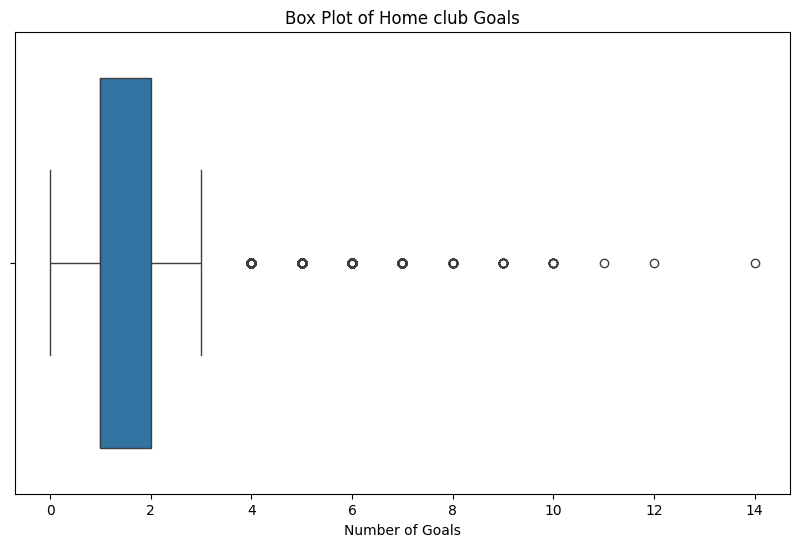

In [27]:
#Prima di eliminare i dati dal nostro database (essendo outliers) ne ho rappresentato un grafico utilizzando un boxplot
plt.figure(figsize=(10, 6))
sns.boxplot(x=df['home_club_goals'])
plt.title("Box Plot of Home club Goals")
plt.xlabel("Number of Goals")
plt.show()

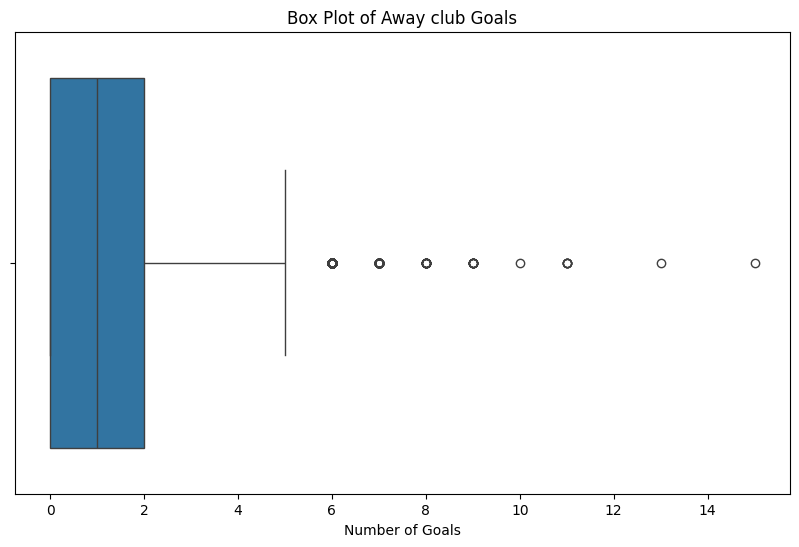

In [28]:
#Prima di eliminare i dati dal nostro database (essendo outliers) ne ho rappresentato un grafico utilizzando un boxplot.
#E' presente una prima rappresentazione che però mostra come è possibile ipotizzare che il numero di goals fatti da una squadra
#fuori casa sia minore
plt.figure(figsize=(10, 6))
sns.boxplot(x=df['away_club_goals'])
plt.title("Box Plot of Away club Goals")
plt.xlabel("Number of Goals")
plt.show()

In [29]:
#La media originale era <home_club_goals=1.553077, away_club_goals=1.221874> ora si è modificata a <home_club_goals=1.500580,
# away_club_goals=1.194210>. Abbiamo eliminato il medesimo range (che corrispondeva a circa il 6% dei casi) ed è ora osservabile
#che la differenza di goal segnati tra casa e fuori casa è elevata
df=df[(df['home_club_goals']<6)&(df['away_club_goals']<6)]
df.describe()

,season,date,home_club_goals,away_club_goals,home_club_position,away_club_position
count,50459.000000,50459,50459.000000,50459.000000,44862.000000,44862.000000
mean,2017.165699,2018-02-23 04:58:15.051427584,1.501516,1.194316,9.321430,9.462708
min,2012.000000,2012-07-09 00:00:00,0.000000,0.000000,1.000000,1.000000
25%,2014.000000,2015-03-21 00:00:00,1.000000,0.000000,5.000000,5.000000
50%,2017.000000,2018-01-16 00:00:00,1.000000,1.000000,9.000000,9.000000
75%,2020.000000,2021-01-27 00:00:00,2.000000,2.000000,14.000000,14.000000
max,2023.000000,2023-11-30 00:00:00,5.000000,5.000000,21.000000,21.000000
std,3.317054,NaN,1.237988,1.136278,5.289958,5.317178


In [30]:
df.shape

(50459, 13)

In [31]:
df

,season,competition_type,round,date,home_club_name,away_club_name,home_club_goals,away_club_goals,home_club_position,away_club_position,home_club_formation,away_club_formation,combined
game_id,,,,,,,,,,,,,
2222597,2012,domestic_league,6. Matchday,2012-08-25,RFK Akhmat Grozny,FK Spartak Moskva,2,1,2.0,5.0,NaN,NaN,2012-08-25_RFK Akhmat Grozny_FK Spartak Moskva
2222627,2012,domestic_league,5. Matchday,2012-08-20,PFK Krylya Sovetov Samara,Amkar Perm,0,2,11.0,10.0,NaN,NaN,2012-08-20_PFK Krylya Sovetov Samara_Amkar Perm
2222658,2012,domestic_league,10. Matchday,2012-09-30,PFK CSKA Moskva,FK Dinamo Moskva,0,2,2.0,13.0,NaN,NaN,2012-09-30_PFK CSKA Moskva_FK Dinamo Moskva
2222683,2012,domestic_league,12. Matchday,2012-10-22,PFK Krylya Sovetov Samara,Volga Nizhniy Novgorod (- 2016),0,1,11.0,16.0,NaN,NaN,2012-10-22_PFK Krylya Sovetov Samara_Volga Niz...
2222685,2012,domestic_league,19. Matchday,2012-12-10,FC Rubin Kazan,FK Spartak Moskva,0,1,7.0,5.0,NaN,NaN,2012-12-10_FC Rubin Kazan_FK Spartak Moskva
...,...,...,...,...,...,...,...,...,...,...,...,...,...
3852607,2022,domestic_league,12. Matchday,2022-10-30,Eindhovense Voetbalvereniging Philips Sport Ve...,Nijmegen Eendracht Combinatie,3,0,2.0,15.0,NaN,NaN,2022-10-30_Eindhovense Voetbalvereniging Phili...
2589097,2015,domestic_league,23. Matchday,2016-02-14,Nijmegen Eendracht Combinatie,Eindhovense Voetbalvereniging Philips Sport Ve...,0,3,8.0,1.0,NaN,NaN,2016-02-14_Nijmegen Eendracht Combinatie_Eindh...
2700827,2016,domestic_league,23. Matchday,2017-02-18,Eindhovense Voetbalvereniging Philips Sport Ve...,Nijmegen Eendracht Combinatie,3,1,3.0,12.0,NaN,NaN,2017-02-18_Eindhovense Voetbalvereniging Phili...


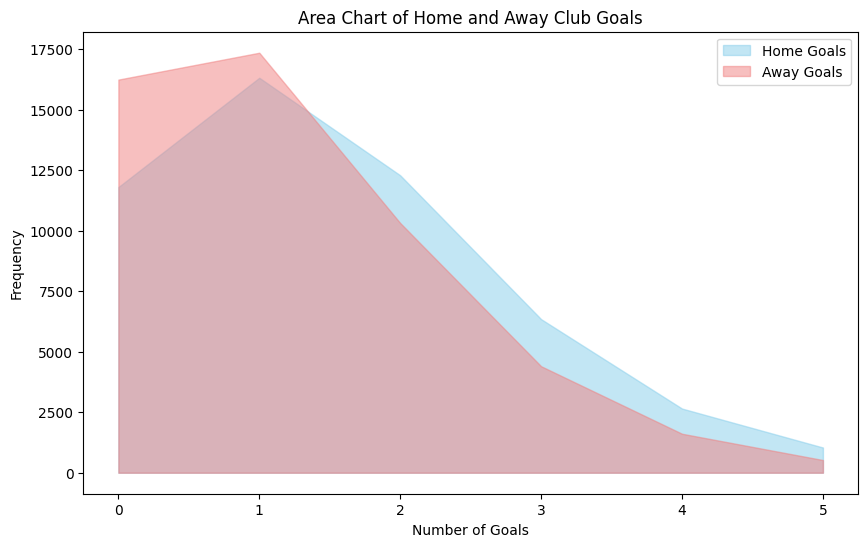

In [32]:
#Degli ottimi valori da mettere a confronto sono il numero di Goal fatti dalla squadra in casa e da quella in esterna.
#Come si può vedere le scquadre in casa fanno più goal.

home_goal_counts = df['home_club_goals'].value_counts().sort_index() # Calcolo la frequenza dei goal fatti in casa
away_goal_counts = df['away_club_goals'].value_counts().sort_index() # Calcolo la frequenza dei goal fatti in esterna

# Creo un DataFrame con le frequenze
goal_counts = pd.DataFrame({
    'Home Goals': home_goal_counts,
    'Away Goals': away_goal_counts
})

# Creo l'area chart
plt.figure(figsize=(10, 6))

plt.fill_between(goal_counts.index, goal_counts['Home Goals'], color='skyblue', alpha=0.5, label='Home Goals')
plt.fill_between(goal_counts.index, goal_counts['Away Goals'], color='lightcoral', alpha=0.5, label='Away Goals')

plt.title("Area Chart of Home and Away Club Goals")
plt.xlabel("Number of Goals")
plt.ylabel("Frequency")
plt.legend()
plt.show()

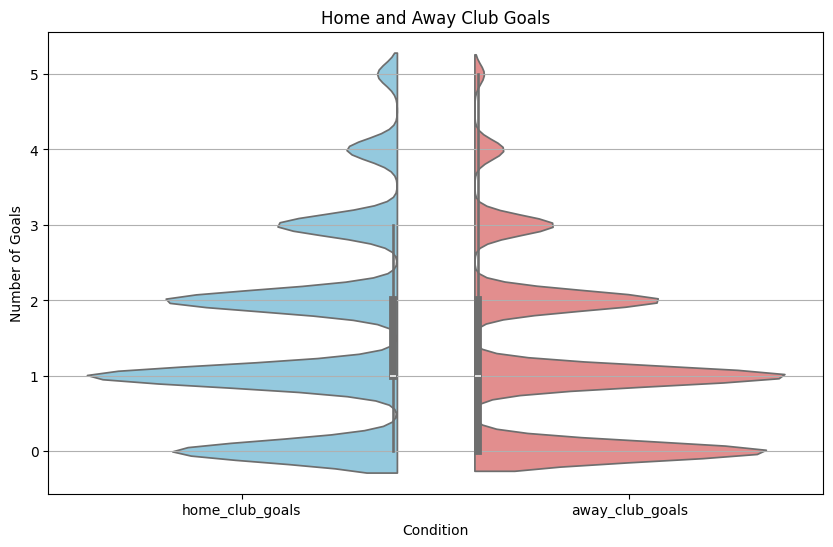

In [33]:
#Un metodo per rappresentare la differenza tra i goal segnati è anche tramite il Violin Plot

df_long = pd.melt(df[['home_club_goals', 'away_club_goals']], var_name='condition', value_name='goals')
plt.figure(figsize=(10, 6))

sns.violinplot(x='condition', y='goals', data=df_long, split=True, hue='condition', 
               palette={"home_club_goals": "skyblue", "away_club_goals": "lightcoral"})

plt.title("Home and Away Club Goals")
plt.xlabel("Condition")
plt.ylabel("Number of Goals")
plt.grid(axis='y')
plt.show()

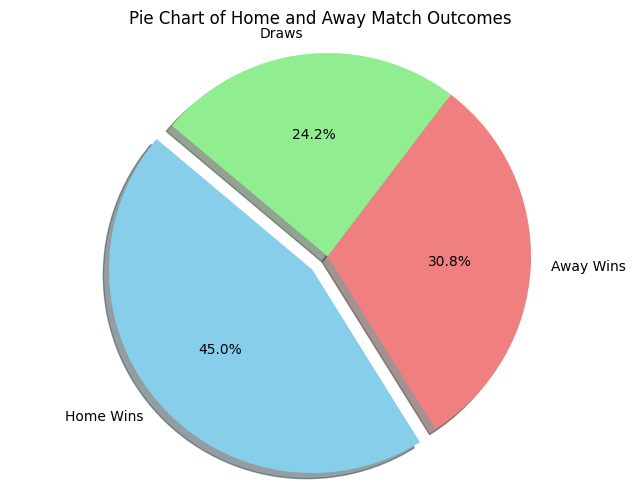

In [34]:
#Ora analizziamo nell'effettivo chi vince di più. Come possiamo vedere la predominanza delle vittorie fatte in casa è
#molto alta, quasi la metà delle volte vince la squadra di casa, mentre solo 1/4 delle volte vince l'ospite!

#Creo delle colonne temporanee per indicare quando si sono fatti più goal in casa che in esterna (vittoria in casa), meno goal in casa
#che in esterna (vittoria in esterna) e gli stessi goal (pareggio)
df['home_win'] = df['home_club_goals'] > df['away_club_goals']
df['away_win'] = df['away_club_goals'] > df['home_club_goals']
df['draw'] = df['home_club_goals'] == df['away_club_goals']

home_wins = df['home_win'].sum() #Conto quante volte ci sono state vittorie in casa
away_wins = df['away_win'].sum() #Conto quante volte si sono state vittorie in esterna
draws = df['draw'].sum() #Conto quante volte si sono stati pareggi

# Creo un grafico a torta con i risultati ottenuti
labels = ['Home Wins', 'Away Wins', 'Draws']
sizes = [home_wins, away_wins, draws]
colors = ['skyblue', 'lightcoral', 'lightgreen']
explode = (0.1, 0, 0)  # Evidenzio la fetta della torta per le vittorie in casa

plt.figure(figsize=(8, 6))
plt.pie(sizes, explode=explode, labels=labels, colors=colors, autopct='%1.1f%%', shadow=True, startangle=140)
plt.title("Pie Chart of Home and Away Match Outcomes")
plt.axis('equal')
plt.show()

In [44]:
#voglio provare a selezionare i games di una determinata nazione X (come esempio presentiamo l'Italia)
#Per prima cosa devo fare dei merge per ottenere tutti i dati necessari
merged_df = pd.merge(games_df, club_domestic_df, left_on='home_club_id', right_on='club_id')
merged_df = pd.merge(merged_df, competitions_domestic_df, left_on='domestic_competition_id', right_on='domestic_league_code')
merged_df

,game_id,competition_id,season,round,date,home_club_id,away_club_id,home_club_goals,away_club_goals,home_club_position,...,home_club_name,away_club_name,aggregate,competition_type,home_club_formation,away_club_formation,club_id,domestic_competition_id,domestic_league_code,country_name
0,2222597,RU1,2012,6. Matchday,2012-08-25,3725,232,2,1,2.0,...,RFK Akhmat Grozny,FK Spartak Moskva,2:1,domestic_league,NaN,NaN,3725,RU1,RU1,Russia
1,2222597,RU1,2012,6. Matchday,2012-08-25,3725,232,2,1,2.0,...,RFK Akhmat Grozny,FK Spartak Moskva,2:1,domestic_league,NaN,NaN,3725,RU1,RU1,Russia
2,2222597,RU1,2012,6. Matchday,2012-08-25,3725,232,2,1,2.0,...,RFK Akhmat Grozny,FK Spartak Moskva,2:1,domestic_league,NaN,NaN,3725,RU1,RU1,Russia
3,2222627,RU1,2012,5. Matchday,2012-08-20,2696,4128,0,2,11.0,...,PFK Krylya Sovetov Samara,Amkar Perm,0:2,domestic_league,NaN,NaN,2696,RU1,RU1,Russia
4,2222627,RU1,2012,5. Matchday,2012-08-20,2696,4128,0,2,11.0,...,PFK Krylya Sovetov Samara,Amkar Perm,0:2,domestic_league,NaN,NaN,2696,RU1,RU1,Russia
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
141864,4164101,CGB,2023,Second Round,2023-08-29,512,1194,6,1,NaN,...,Stoke City,NaN,6:1,other,4-2-3-1,4-2-3-1,512,GB1,GB1,England
141865,4013659,FAC,2022,Fourth Round,2023-01-29,512,3684,3,1,NaN,...,Stoke City,NaN,3:1,domestic_cup,NaN,NaN,512,GB1,GB1,England
141866,4013659,FAC,2022,Fourth Round,2023-01-29,512,3684,3,1,NaN,...,Stoke City,NaN,3:1,domestic_cup,NaN,NaN,512,GB1,GB1,England
141867,4013659,FAC,2022,Fourth Round,2023-01-29,512,3684,3,1,NaN,...,Stoke City,NaN,3:1,domestic_cup,NaN,NaN,512,GB1,GB1,England


In [49]:
#ora pulisco i dati togliendo le colonne non utili, i valori nulli e i duplicati
merged_df=merged_df[['game_id','home_club_name', 'away_club_name', 'home_club_goals', 'away_club_goals', 'domestic_competition_id', 'country_name']]
merged_df=merged_df.drop_duplicates().dropna()
merged_df

,game_id,home_club_name,away_club_name,home_club_goals,away_club_goals,domestic_competition_id,country_name
0,2222597,RFK Akhmat Grozny,FK Spartak Moskva,2,1,RU1,Russia
3,2222627,PFK Krylya Sovetov Samara,Amkar Perm,0,2,RU1,Russia
6,2222658,PFK CSKA Moskva,FK Dinamo Moskva,0,2,RU1,Russia
9,2222683,PFK Krylya Sovetov Samara,Volga Nizhniy Novgorod (- 2016),0,1,RU1,Russia
12,2222685,FC Rubin Kazan,FK Spartak Moskva,0,1,RU1,Russia
...,...,...,...,...,...,...,...
141717,3852607,Eindhovense Voetbalvereniging Philips Sport Ve...,Nijmegen Eendracht Combinatie,3,0,NL1,Netherlands
141720,2589097,Nijmegen Eendracht Combinatie,Eindhovense Voetbalvereniging Philips Sport Ve...,0,3,NL1,Netherlands
141723,2700827,Eindhovense Voetbalvereniging Philips Sport Ve...,Nijmegen Eendracht Combinatie,3,1,NL1,Netherlands
141726,3852741,Nijmegen Eendracht Combinatie,Eindhovense Voetbalvereniging Philips Sport Ve...,2,4,NL1,Netherlands


In [50]:
#seleziono la naizone Italia e così ho tutti i dati dei games italiani
italy_games=merged_df[merged_df['country_name']=='Italy']
italy_games

,game_id,home_club_name,away_club_name,home_club_goals,away_club_goals,domestic_competition_id,country_name
371,2251356,Genoa Cricket and Football Club,Associazione Calcio Fiorentina,0,1,IT1,Italy
374,2251368,Società Sportiva Calcio Napoli,Torino Calcio,1,1,IT1,Italy
377,2251398,Palermo FC,Catania FC,3,1,IT1,Italy
380,2251410,Società Sportiva Calcio Napoli,Delfino Pescara 1936,5,1,IT1,Italy
383,2251417,Palermo FC,Juventus Football Club,0,1,IT1,Italy
...,...,...,...,...,...,...,...
141410,3614621,Società Sportiva Calcio Napoli,Bologna Football Club 1909,3,0,IT1,Italy
141433,4103506,Verona Hellas Football Club,Bologna Football Club 1909,0,0,IT1,Italy
141595,3433436,Spezia Calcio,Benevento Calcio,1,1,IT1,Italy
141637,4161041,Unione Sportiva Sassuolo Calcio,Spezia Calcio,5,4,IT1,Italy


In [144]:
df.to_csv('new_games.csv', index=False)

In [145]:
type=games_df[['competition_type']].drop_duplicates()
type

,competition_type
0,domestic_league
169,international_cup
173,domestic_cup
386,other


In [146]:
#Vogio provare a cercare i vari giocatori delle nazionali, non essendo presente l'informazione nel csv dei players e non essendo
#ricavabile dai clu (i quali dicono solo quanti ce ne sono nella loro squadra).
#per fare ciò è necessario importare diversi set di dati:
#-games:game_id, competition_type =(='international_cup'/'other') e competition_id
#-appearancess: game_id(merge con games), player_id, player_name, palyer_club_id
#competitions: competition_id (merge con games) e competition_name
#clubs: club_id, name

#games
game_internationals=games_df[['game_id','competition_type', 'competition_id']]
game_internationals=game_internationals[(game_internationals['competition_type']=='international_cup')|(game_internationals['competition_type']=='other')]
game_internationals

,game_id,competition_type,competition_id
169,2262154,international_cup,CL
170,2262190,international_cup,CL
171,2262441,international_cup,EL
181,2284471,international_cup,EL
182,2284475,international_cup,EL
...,...,...,...
65205,2262451,international_cup,EL
65206,2469213,international_cup,ELQ
65211,2367292,international_cup,EL
65213,3092951,international_cup,CLQ


In [158]:
#appearancess
collection_appearances=db['Appearances']
documents=collection_appearances.find()
appearances_df=pd.DataFrame(list(documents)).drop('_id', axis=1)

appearances_df=appearances_df[['game_id', 'player_id', 'player_name', 'player_club_id']]
appearances_df.rename(columns={'player_club_id':'club_id'}, inplace=True)
appearances_df

,game_id,player_id,player_name,club_id
0,2231978,38004,Aurélien Joachim,853
1,2233748,79232,Ruslan Abyshov,8841
2,2234413,42792,Sander Puri,6251
3,2234418,73333,Vegar Hedenstad,1274
4,2234421,122011,Markus Henriksen,195
...,...,...,...,...
1507346,4172154,659813,Piero Hincapié,15
1507347,4172154,696027,Ayman Aourir,15
1507348,4172154,7161,Jonas Hofmann,15
1507349,4172154,743395,Noah Mbamba,15


In [159]:
#competitions
competitions_international_df=competitions_df[['competition_id','name']].copy()
competitions_international_df.rename(columns={'name':'competition_name'}, inplace=True)
competitions_international_df

,competition_id,competition_name
0,CIT,italy-cup
1,NLSC,johan-cruijff-schaal
2,GRP,kypello-elladas
3,POSU,supertaca-candido-de-oliveira
4,RUSS,russian-super-cup
5,SUC,supercopa
6,USC,uefa-super-cup
7,DK1,superligaen
8,EL,europa-league
9,ES1,laliga


In [160]:
clubs_international_df=club_df[['club_id','name']].copy()
clubs_international_df.rename(columns={'name':'club_name'}, inplace=True)
clubs_international_df

,club_id,club_name
0,105,Sportverein Darmstadt 1898 e. V.
1,11127,FK Ural Yekaterinburg
2,114,Beşiktaş Jimnastik Kulübü
3,12,Associazione Sportiva Roma
4,148,Tottenham Hotspur Football Club
...,...,...
421,68608,CF Os Belenenses
422,724,Football Club Volendam
423,800,Atalanta Bergamasca Calcio S.p.a.
424,979,Moreirense Futebol Clube


In [187]:
#Per prima cosa analizzo le 10 squadre che hanno partecipato di più a competizioni internazionali
top_ten_club=pd.merge(game_internationals, appearances_df, on='game_id', how='inner')
comp=top_ten_club.groupby('club_id').size().reset_index(name='n_competition')
top_ten_club=pd.merge(top_ten_club, comp, on='club_id', how='left')
top_ten_club=top_ten_club.sort_values(by='n_competition', ascending = False)
top_ten_club=top_ten_club[['club_id', 'n_competition']].drop_duplicates().head(10)
top_ten_club=pd.merge(top_ten_club, clubs_international_df, on='club_id', how='inner')
top_ten_club=top_ten_club.sort_values(by='n_competition', ascending = False)
top_ten_club

,club_id,n_competition,club_name
0,418,2247,Real Madrid Club de Fútbol
1,368,2049,Sevilla Fútbol Club S.A.D.
2,27,2019,FC Bayern München
3,371,1971,The Celtic Football Club
4,131,1939,Futbol Club Barcelona
5,294,1924,Sport Lisboa e Benfica
6,683,1903,Olympiakos Syndesmos Filathlon Peiraios
7,610,1815,AFC Ajax Amsterdam
8,281,1785,Manchester City Football Club
9,985,1776,Manchester United Football Club


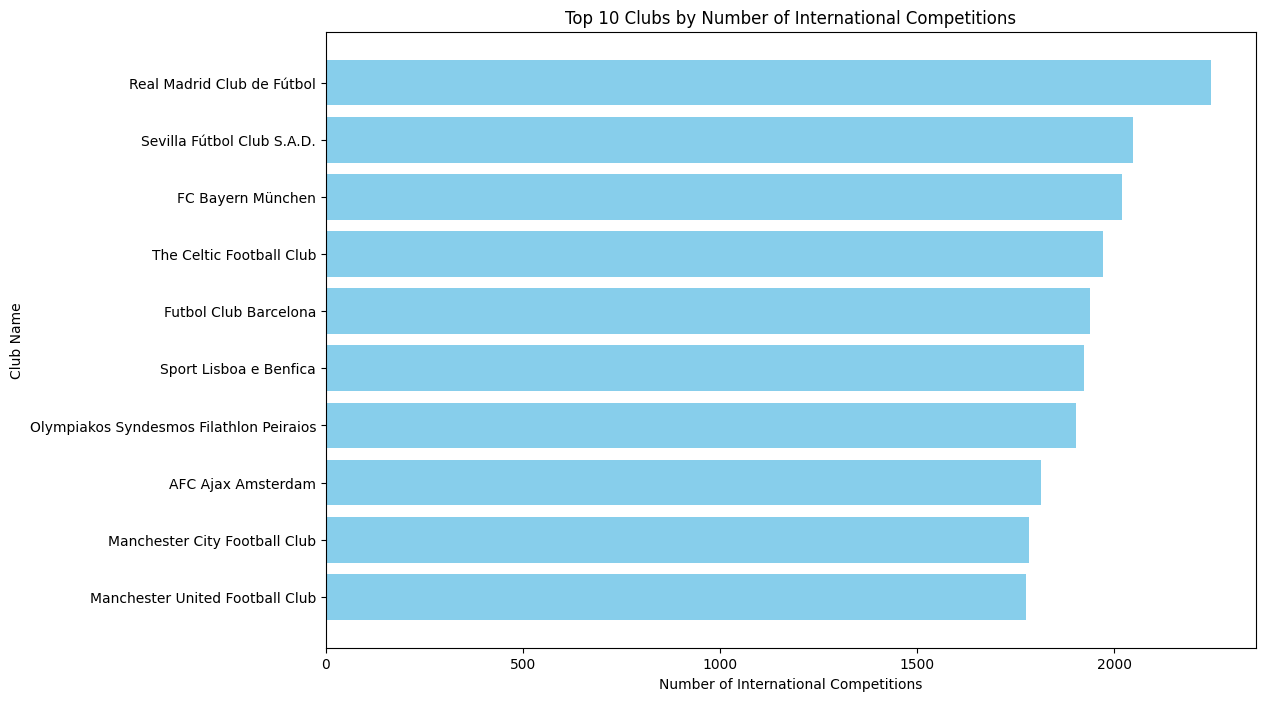

In [191]:
#grafico
plt.figure(figsize=(12, 8))
plt.barh(top_ten_club['club_name'], top_ten_club['n_competition'], color='skyblue')
plt.xlabel('Number of International Competitions')
plt.ylabel('Club Name')
plt.title('Top 10 Clubs by Number of International Competitions')
plt.gca().invert_yaxis()
plt.show()

In [193]:
#Adesso analizzo i 10 giocatori che hanno partecipato di più a competizioni internazionali. Logicamente fanno tutti parte delle
#top ten club
top_ten_player=pd.merge(game_internationals, appearances_df, on='game_id', how='inner')
comp=top_ten_player.groupby('player_id').size().reset_index(name='n_competition')
top_ten_player=pd.merge(top_ten_player, comp, on='player_id', how='left')
top_ten_player=top_ten_player.sort_values(by='n_competition', ascending = False)
top_ten_player=top_ten_player[['player_name', 'n_competition']].drop_duplicates().head(10)
top_ten_player

,player_name,n_competition
100576,Toni Kroos,139
11140,Ivan Rakitic,127
67728,Thomas Müller,126
81104,Robert Lewandowski,125
45134,Luka Modric,124
18863,Karim Benzema,123
53299,Cristiano Ronaldo,123
101093,David Alaba,119
112519,Casemiro,119
65210,Sergio Busquets,115


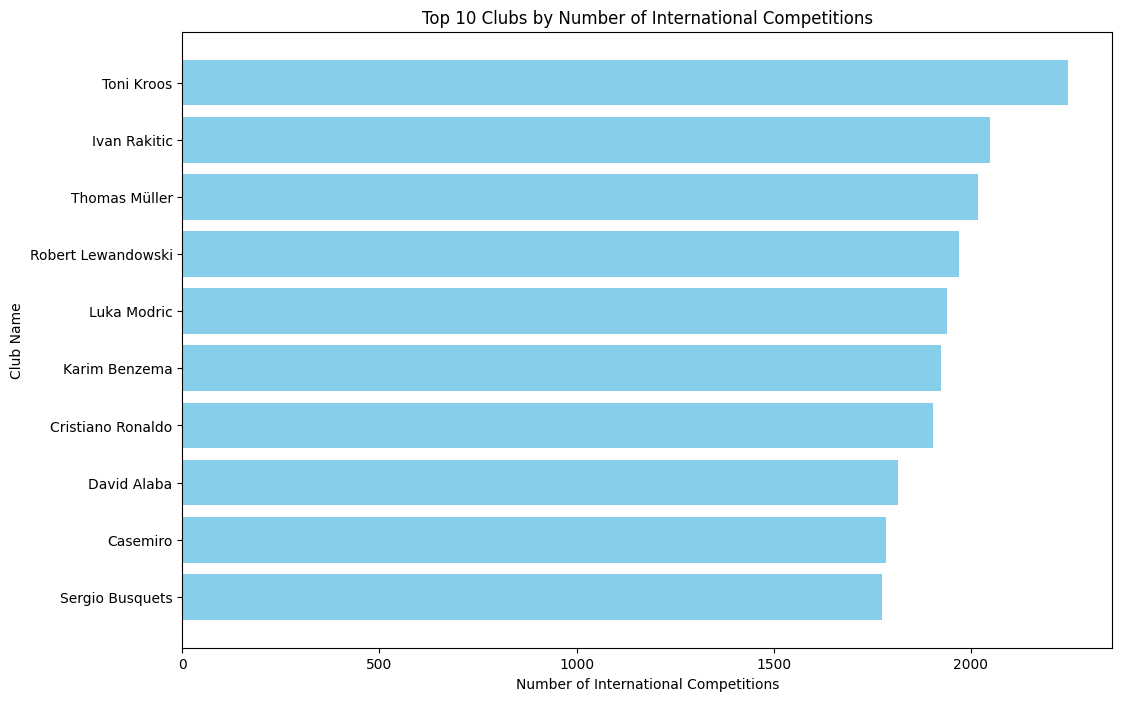

In [195]:
#grafico
plt.figure(figsize=(12, 8))
plt.barh(top_ten_player['player_name'], top_ten_club['n_competition'], color='skyblue')
plt.xlabel('Number of International Competitions')
plt.ylabel('Club Name')
plt.title('Top 10 Clubs by Number of International Competitions')
plt.gca().invert_yaxis()
plt.show()

In [33]:
#Ora voglio fare un'analisi in base alle formazioni, quindi inizio a cancellare quelle vuote
df=df[~df['home_club_formation'].isna()]
df=df[~df['away_club_formation'].isna()]

In [85]:
df.describe()

,season,home_club_goals,away_club_goals,home_club_position,away_club_position
count,1799.0,1799.000000,1799.000000,1556.000000,1556.000000
mean,2023.0,1.578655,1.279600,9.048201,9.297558
std,0.0,1.271013,1.184898,5.210883,5.222831
min,2023.0,0.000000,0.000000,1.000000,1.000000
25%,2023.0,1.000000,0.000000,5.000000,5.000000
50%,2023.0,1.000000,1.000000,9.000000,9.000000
75%,2023.0,2.000000,2.000000,13.000000,14.000000
max,2023.0,5.000000,5.000000,20.000000,20.000000


In [86]:
df.shape

(1799, 16)

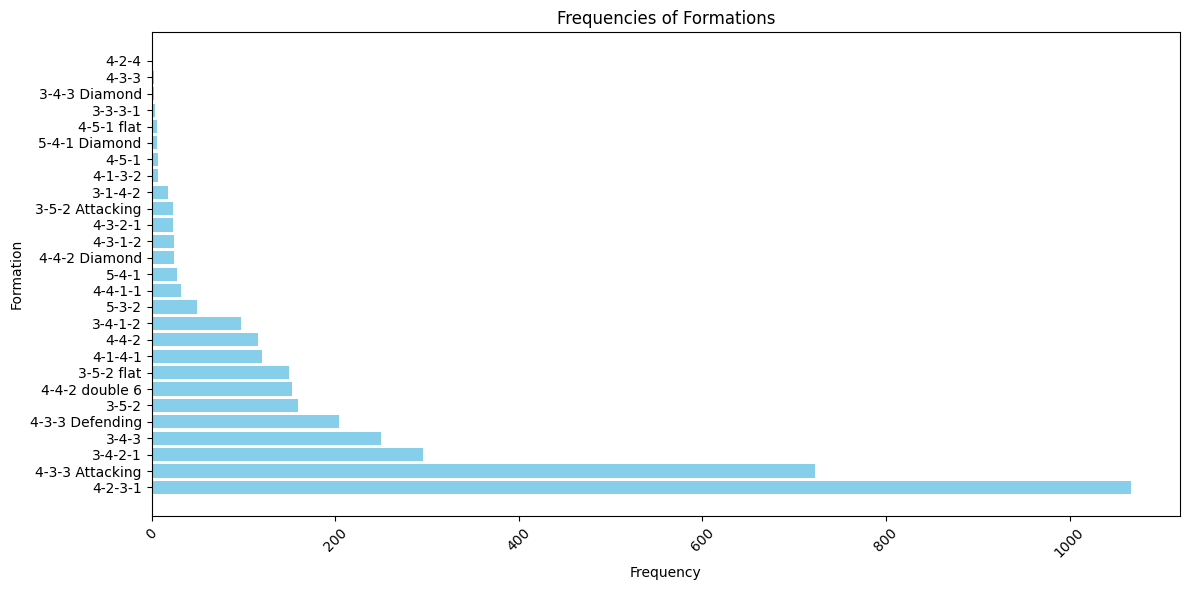

In [87]:
# Unisco le colonne away_club_formation e home_club_formation in una singola serie per analizzarle tutte insieme. Si può vedere che quella più usata
#è 4-2-3-1. Sarà anche quella più vincente?

all_formations = pd.concat([df['away_club_formation'], df['home_club_formation']]) #Concateno i due valori per analizzarli insieme

formation_counts = all_formations.value_counts()

# Creo il grafico a barre delle formazioni più usate
plt.figure(figsize=(12, 6))
plt.barh(formation_counts.index, formation_counts.values, color='skyblue')
plt.title('Frequencies of Formations')
plt.xlabel('Frequency')
plt.ylabel('Formation')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

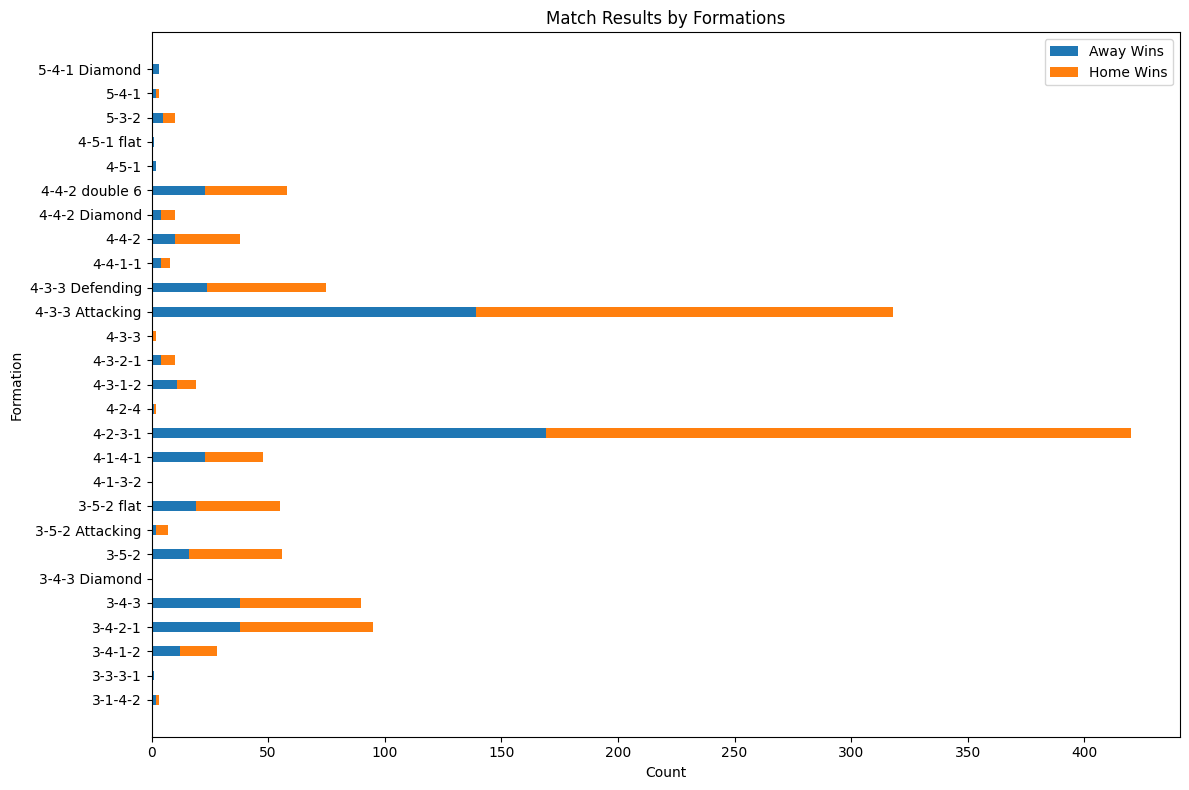

In [88]:
#Creiamo uno schema per osservare quali sono le formazioni più vincenti. Effettivamente la 4-2-3-1 è la più vincente, anche se
#potrebbe essere dovuto al fatto che è anche quello più usato

#Creo delle colonne temporanee per indicare quando si sono fatti più goal in casa che in esterna (vittoria in casa), meno goal in casa
#che in esterna (vittoria in esterna) e gli stessi goal (pareggio)
df['home_win'] = df['home_club_goals'] > df['away_club_goals']
df['away_win'] = df['away_club_goals'] > df['home_club_goals']
df['draw'] = df['home_club_goals'] == df['away_club_goals']

# Raggruppo per formazione away_club_formation e conto le vittorie in trasferta (away_win)
away_win_counts = df.groupby('away_club_formation')['away_win'].sum().reset_index()
away_win_counts.columns = ['formation', 'away_win_counts']

# Raggruppo per formazione home_club_formation e conto le vittorie in casa (home_win)
home_win_counts = df.groupby('home_club_formation')['home_win'].sum().reset_index()
home_win_counts.columns = ['formation', 'home_win_counts']

# Unire i conteggi in un unico DataFrame
formations_df = pd.merge(away_win_counts, home_win_counts, on='formation', how='outer')

# Riempire i valori NaN con 0
formations_df = formations_df.fillna(0)

# Creare il grafico a barre orizzontali
formations = formations_df['formation']
plt.figure(figsize=(12, 8))

bar_width = 0.4  # Larghezza delle barre

# Grafico per le vittorie in trasferta
plt.barh(formations, formations_df['away_win_counts'], height=bar_width, label='Away Wins', align='center')

# Grafico per le vittorie in casa, posizionato dopo le vittorie in trasferta
plt.barh(formations, formations_df['home_win_counts'], left=formations_df['away_win_counts'], height=bar_width, label='Home Wins', align='center')

plt.title('Match Results by Formations')
plt.xlabel('Count')
plt.ylabel('Formation')
plt.legend()
plt.tight_layout()
plt.show()

In [89]:
#Ora voglio trovere le squadre che hanno fatto più goal. Per una migliore visualizzazione seleziono solo le prime 50

# Raggruppo per squadra di casa e sommare i gol segnati in casa
home_goals = df.groupby('home_club_name')['home_club_goals'].sum().reset_index()

# Raggruppo per squadra in trasferta e sommare i gol segnati in trasferta
away_goals = df.groupby('away_club_name')['away_club_goals'].sum().reset_index()

# Rinomino le colonne per evitare conflitti
home_goals.columns = ['club_name', 'home_goals']
away_goals.columns = ['club_name', 'away_goals']

# Unisco i dati di casa e trasferta
total_goals = pd.merge(home_goals, away_goals, on='club_name', how='outer').fillna(0)

# Convertire le colonne home_goals e away_goals in int
total_goals['home_goals'] = total_goals['home_goals'].astype(int)
total_goals['away_goals'] = total_goals['away_goals'].astype(int)

# Calcolare i gol totali
total_goals['total_goals'] = total_goals['home_goals'] + total_goals['away_goals']

# Ordino le squadre in base ai gol totali in ordine decrescente e selezionare le prime 50
top_50_teams = total_goals.sort_values(by='total_goals', ascending=False).head(50)

La squadra con più gol è Eindhovense Voetbalvereniging Philips Sport Vereniging con 57 gol.


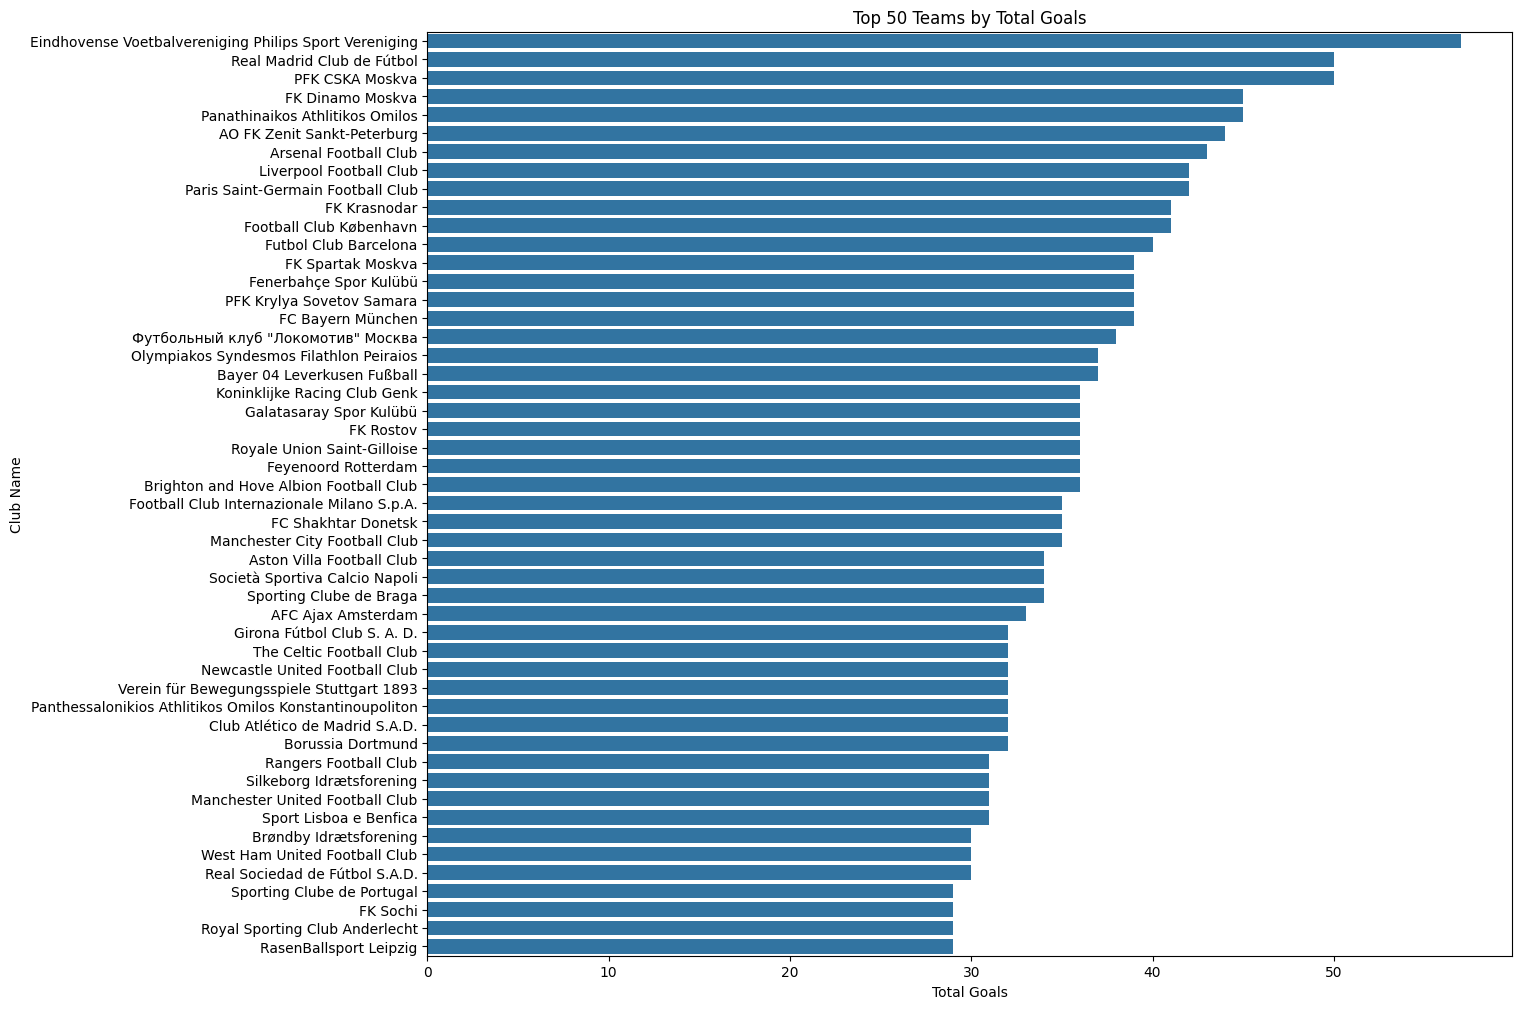

In [66]:
#Così visualizziamo quali sono le 50 squadre con più goal
print(f"La squadra con più gol è {top_team['club_name']} con {top_team['goals']} gol.")
plt.figure(figsize=(14, 12))
sns.barplot(x='total_goals', y='club_name', data=top_50_teams)
plt.title('Top 50 Teams by Total Goals')
plt.xlabel('Total Goals')
plt.ylabel('Club Name')
plt.show()

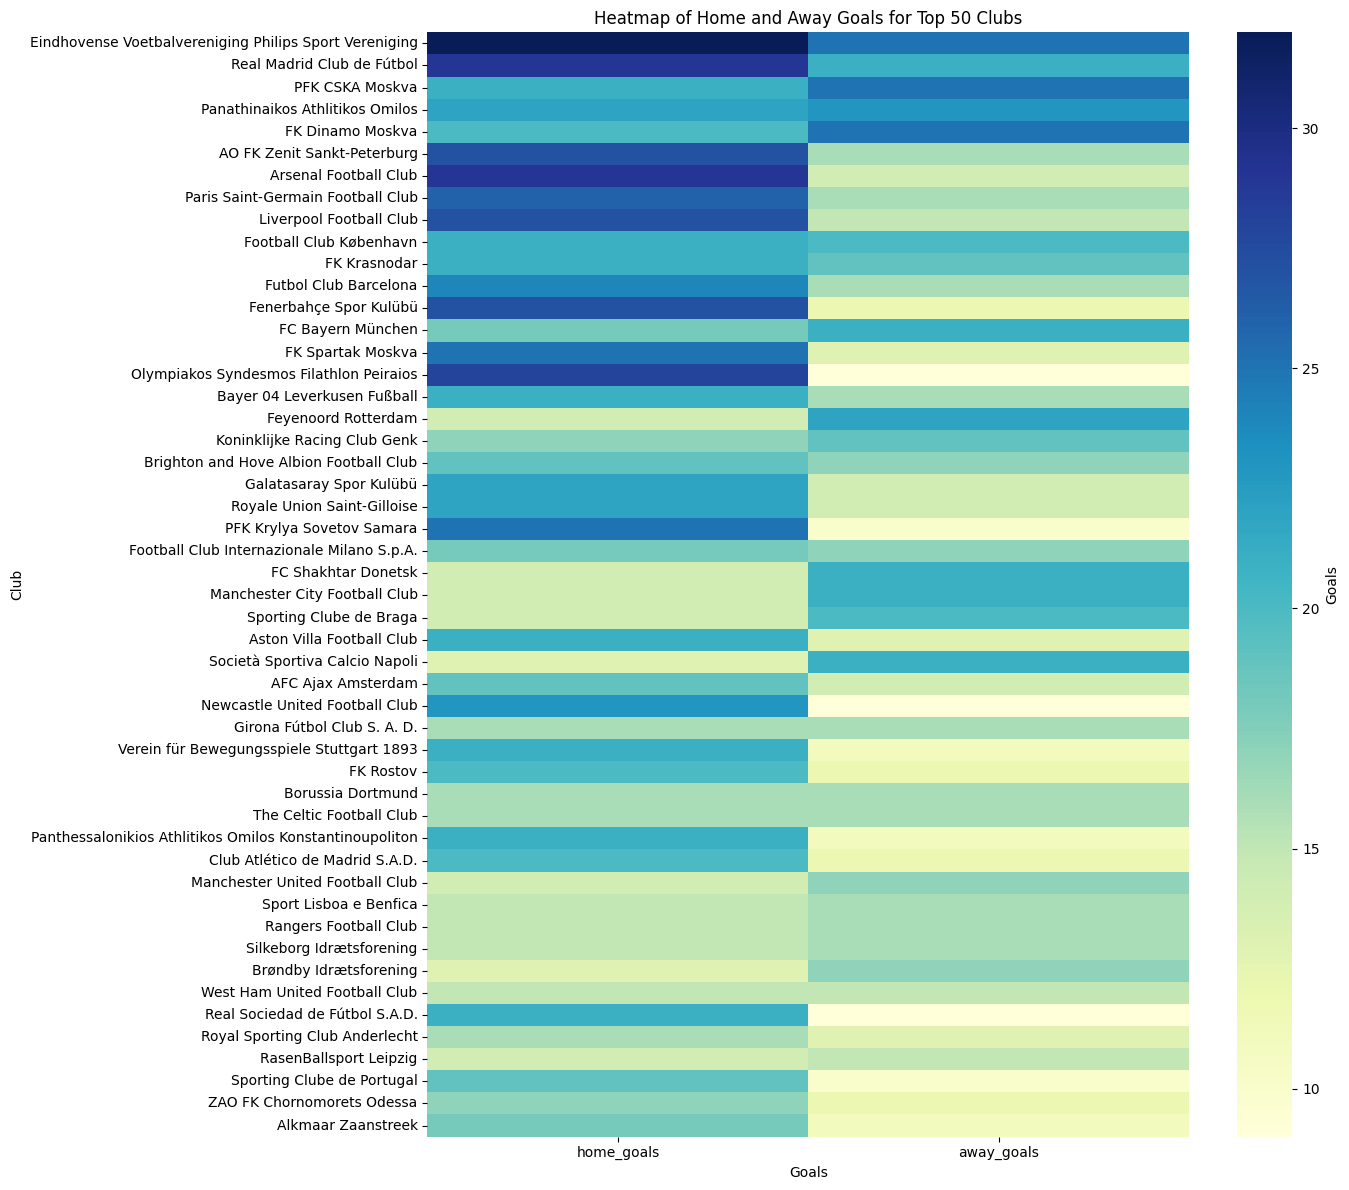

In [90]:
#Così visualizziamo quali sono le 50 squadre con più goal vedendo anche la differenza tra i goal in interna ed esterna

heatmap_data = top_50_teams[['club_name', 'home_goals', 'away_goals']].set_index('club_name')
plt.figure(figsize=(14, 12))
sns.heatmap(heatmap_data, annot=False, cmap="YlGnBu", cbar=True, cbar_kws={'label': 'Goals'})
plt.title('Heatmap of Home and Away Goals for Top 50 Clubs')
plt.ylabel('Club')
plt.xlabel('Goals')
plt.tight_layout()
plt.show()